# Data-driven design in Godot

**The principle:** write code to build an *air-tight toolbox*, then build the game *with the toolbox in the editor*, not with more code.

| Section | What you get |
|---|---|
| 1 | The idea in one picture |
| 2 | Vocabulary: mech bug vs content bug |
| 3 | Where this repo is today (before / after) |
| 4 | "Won't resources clutter my project?" |
| 5 | The Godot building blocks |
| 6 | The lambda queue pattern |
| 7 | Toy version you can run |
| 8 | Making it air tight: validation |
| 9 | Best practices and traps |
| 10 | Suggested first steps |

## 1. The idea in one picture

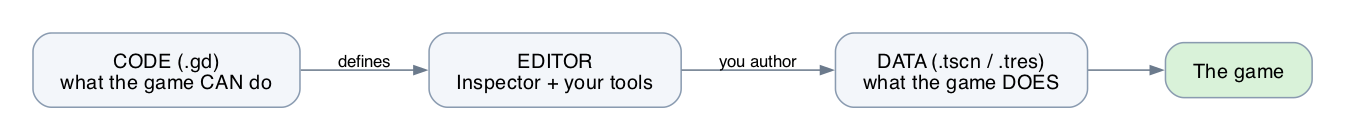

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  code   [label="CODE (.gd)\nwhat the game CAN do"];
  editor [label="EDITOR\nInspector + your tools"];
  data   [label="DATA (.tscn / .tres)\nwhat the game DOES"];
  game   [label="The game", fillcolor="#d9f2d9"];
  code -> editor [label="defines"];
  editor -> data [label="you author"];
  data -> game;
}
```

</details>

| Name people use | What it means |
|---|---|
| **Data-driven design** | Behaviour lives in data, code only interprets it |
| **Mechanism vs policy** | Code = *how* things happen. Data = *what* happens and *when* |
| **Command pattern (serialized)** | Each action ("say", "move") is an object you can store in a list |
| **Engine / content split** | The same idea, as studios describe their teams |

RPG Maker's event editor is the classic example: a fixed list of commands, and the whole game is made by queueing them.

## 2. Vocabulary

| Term | Also called | Lives in | Fixed by |
|---|---|---|---|
| **Mech bug** | code bug | `.gd` files (`core/`, lambdas, runners, tools) | Editing code. Every use is fixed at once |
| **Content bug** | data bug | `.tscn` / `.tres` / Inspector values | Editing data in the editor. No code change |
| **Mech gap** | missing feature | nowhere yet | Adding a new lambda type. Not a bug |
| **Silent content bug** | unvalidated data | data, but the code let it through | Fix the data **and** add a check |

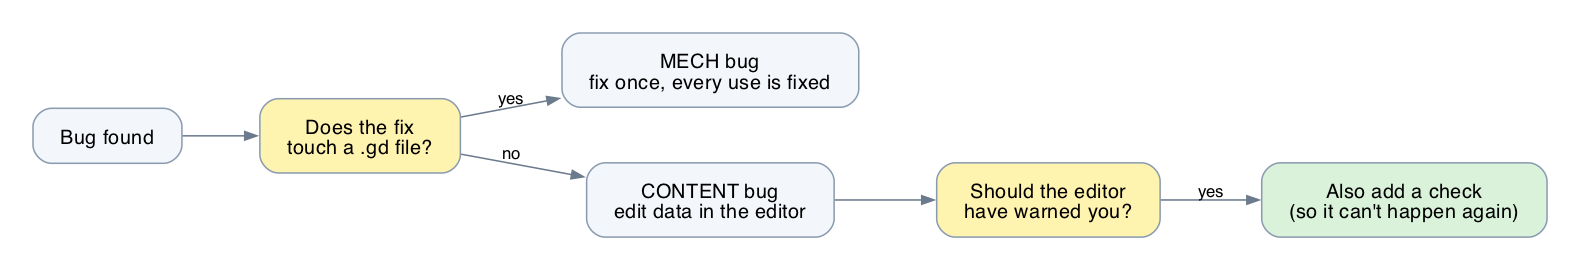

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  bug  [label="Bug found"];
  q    [label="Does the fix\ntouch a .gd file?", fillcolor="#fff3b0"];
  mech [label="MECH bug\nfix once, every use is fixed"];
  cont [label="CONTENT bug\nedit data in the editor"];
  q2   [label="Should the editor\nhave warned you?", fillcolor="#fff3b0"];
  val  [label="Also add a check\n(so it can't happen again)", fillcolor="#d9f2d9"];
  bug -> q;
  q -> mech [label="yes"];
  q -> cont [label="no"];
  cont -> q2;
  q2 -> val [label="yes"];
}
```

</details>

**Why this matters:** you always know which side to look at, and the mech side stays small enough to test properly.

## 3. Where this repo is today

Content is currently written as code. This is a real event from `viewports/rpgm/_rpgm_map.tscn` (a GDScript embedded in the scene):

```gdscript
func _on_action():
	await get_lambdas().show_messages(["Wait here."])
	await get_tree().create_timer(1).timeout
	await get_event().get_mover().walk(Vector2i(-1, 0))
	await get_tree().create_timer(1).timeout
	await get_map().find_event("_npc_1_1").get_mover().walk(Vector2i(1, 0))
	...
	await get_lambdas().show_messages(["Okay you can go now."])
```

The same event as data would be a list in the Inspector:

| # | Lambda | Fields |
|---|---|---|
| 0 | Say | `"Wait here."` |
| 1 | Wait | `1.0` s |
| 2 | Walk | who: *this event*, by: `(-1, 0)` |
| 3 | Wait | `1.0` s |
| 4 | Walk | who: `_npc_1_1`, by: `(1, 0)` |
| ... | ... | ... |
| n | Say | `"Okay you can go now."` |

| | Code version (today) | Data version |
|---|---|---|
| A typo in content | Script error at runtime | Impossible, or an editor warning |
| Forgetting an `await` | Steps overlap, hard to spot | Cannot happen, the runner awaits |
| Reorder steps | Cut and paste lines | Drag rows |
| Check every event in the game | Not practical | One loop over the data |

**Good news:** `_RPGM_Lambdas` already *is* the mechanism (`show_messages`, `move_event`, `transport_player`, `fade_in`...). What's missing is only the data layer on top of it.

## 4. "Won't resources clutter my project?"

No. A `Resource` does **not** have to be a file.

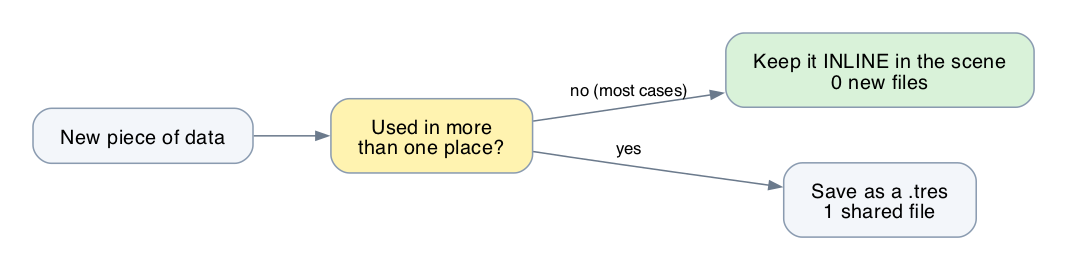

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  new  [label="New piece of data"];
  q    [label="Used in more\nthan one place?", fillcolor="#fff3b0"];
  inl  [label="Keep it INLINE in the scene\n0 new files", fillcolor="#d9f2d9"];
  tres [label="Save as a .tres\n1 shared file"];
  new -> q;
  q -> inl  [label="no (most cases)"];
  q -> tres [label="yes"];
}
```

</details>

| Kind | Where it is stored | New files | Use for |
|---|---|---|---|
| **Inline sub-resource** | Inside the `.tscn` that uses it | 0 | An event's lambda queue, one-off settings |
| **`.tres` file** | Its own file | 1 | Things reused across scenes: an item, an enemy's stats, a shared cutscene |

So the file count grows with your **lambda types** (code, a handful, one folder), not with your **content** (hundreds of events, zero extra files).

| Folder idea | Contains | Grows with |
|---|---|---|
| `viewports/rpgm/lambdas/` | One small `.gd` per lambda type | New mechanisms (slow) |
| `viewports/rpgm/data/` | `.tres` files that are genuinely shared | Shared content (slow) |
| the `.tscn` files | All one-off content, inline | Content (free) |

## 5. The Godot building blocks

| Tool | What it gives you | Effort |
|---|---|---|
| `class_name X extends Resource` | A new data type the Inspector understands | Tiny |
| `@export var steps: Array[X]` | An add / remove / reorder list in the Inspector, with a "New ..." dropdown of every subclass of `X` | Tiny |
| `@export_group`, `@export_range`, `@export_enum`, `@export_file` | Tidy, constrained fields, so bad values can't be typed | Tiny |
| `@tool` + `_get_configuration_warnings()` | A yellow warning triangle on the node when its data is wrong | Small |
| `_validate_property()` | Hide or lock fields that don't apply | Small |
| `EditorInspectorPlugin` / `EditorPlugin` | Custom Inspector widgets, your own editor panels | Bigger, do it last |

The first three rows already get you most of an RPG Maker style event editor, with no plugin code.

One thing to know: a `Callable` cannot be saved in a scene. That is why a queue of raw `Callable`s (like `_Core_Turn_Lambda` takes) can only be built in code, and why the data version needs `Resource` objects instead.

## 6. The lambda queue pattern

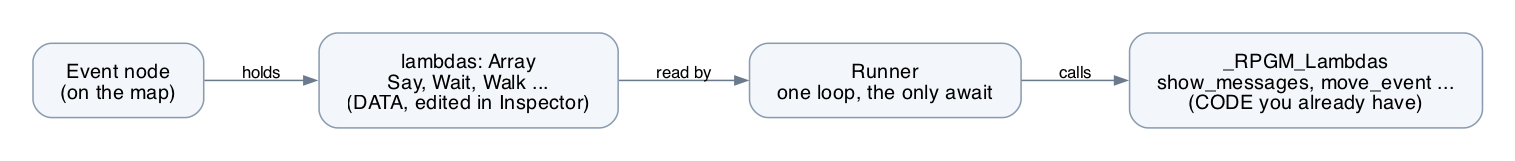

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  event  [label="Event node\n(on the map)"];
  queue  [label="lambdas: Array\nSay, Wait, Walk ...\n(DATA, edited in Inspector)"];
  runner [label="Runner\none loop, the only await"];
  mech   [label="_RPGM_Lambdas\nshow_messages, move_event ...\n(CODE you already have)"];
  event -> queue [label="holds"];
  queue -> runner [label="read by"];
  runner -> mech [label="calls"];
}
```

</details>

**Three small pieces.** Names are suggestions only.

**a) A base type** (one file):

```gdscript
class_name _RPGM_Lambda extends Resource

func run(_script: _RPGM_Script) -> void:
	pass
```

**b) One tiny file per lambda type.** Each is just fields plus one call into code you already have:

```gdscript
class_name _RPGM_Lambda_Say extends _RPGM_Lambda

@export var messages: Array[String] = []

func run(script: _RPGM_Script) -> void:
	await script.get_lambdas().show_messages(messages)
```

**c) One runner**, as a common script next to the talker:

```gdscript
class_name _RPGM_Common_Script_Queue extends _RPGM_Script

@export var on_action: Array[_RPGM_Lambda] = []

func _on_action():
	for lambda in on_action:
		await lambda.run(self)
```

After that, any event on the map gets a queue by attaching the runner and clicking **Add Element** in the Inspector.

| Your example | Lambda type | Calls (already exists) |
|---|---|---|
| "say blah" | `Say` | `show_messages` |
| "move" | `Walk` | `mover.walk` / `move_event` |
| "show inventory scene" | `Open Viewport` | `get_core().add_viewport` |
| pause | `Wait` | a timer |
| anything odd | `Call` (escape hatch) | a method name on the script |

## 7. Toy version you can run

The same pattern in ten lines of Python, so you can feel the split. The **mechanism** is the functions. The **content** is the list.

In [ ]:
# ---- MECHANISM (code): what the game CAN do ----
def say(text):          print(f"  [window] {text}")
def wait(seconds):      print(f"  ...wait {seconds}s")
def walk(who, by):      print(f"  {who} walks {by}")
def open_scene(scene):  print(f"  >> opens the {scene} scene")

MECH = {"say": say, "wait": wait, "walk": walk, "open_scene": open_scene}

def run(queue):
	for step in queue:
		step = dict(step)
		MECH[step.pop("do")](**step)

# ---- CONTENT (data): what the game DOES ----
npc_event = [
	{"do": "say",  "text": "Wait here."},
	{"do": "wait", "seconds": 1},
	{"do": "walk", "who": "npc", "by": (-1, 0)},
	{"do": "open_scene", "scene": "inventory"},
]

run(npc_event)

  [window] Wait here.
  ...wait 1s
  npc walks (-1, 0)
  >> opens the inventory scene


In [ ]:
# ----- student scratchpad ----- 

Because content is data, a program can **check all of it before the game runs**. Code-as-content can't be checked like this.

In [ ]:
import inspect

def check(queue):
	problems = []
	for i, step in enumerate(queue):
		name = step.get("do")
		if name not in MECH:
			problems.append(f"step {i}: unknown lambda '{name}'")
			continue
		needed = set(inspect.signature(MECH[name]).parameters)
		given = set(step) - {"do"}
		if needed - given: problems.append(f"step {i} ({name}): missing {sorted(needed - given)}")
		if given - needed: problems.append(f"step {i} ({name}): unknown field {sorted(given - needed)}")
		if name == "say" and not step.get("text"): problems.append(f"step {i} (say): empty text")
	return problems or ["all good"]

broken_event = [
	{"do": "say",  "text": ""},              # content bug: empty text
	{"do": "wlak", "who": "npc"},            # content bug: typo
	{"do": "walk", "who": "npc"},            # content bug: missing 'by'
]

print("npc_event:   ", check(npc_event))
print("broken_event:")
for p in check(broken_event): print("  -", p)

npc_event:    ['all good']
broken_event:
  - step 0 (say): empty text
  - step 1: unknown lambda 'wlak'
  - step 2 (walk): missing ['by']


In [ ]:
# ----- student scratchpad ----- 

In Godot the Inspector prevents the typo and the missing field for free (you pick `Walk` from a dropdown and the fields are typed). You only write checks for the leftovers, like "empty text".

## 8. Making it air tight: validation

Splitting code and data makes checking *possible*. The checks are what make it *air tight*.

| Layer | What it catches | Godot tool |
|---|---|---|
| **1. Can't be typed** | Wrong type, out of range, unknown lambda | Typed `@export`, `@export_range`, `@export_enum` |
| **2. Warned in the editor** | Empty text, missing target, empty queue | `_get_configuration_warnings()` on a `@tool` script |
| **3. Checked in bulk** | Any bad data in any scene | A small script that loads every map and calls each lambda's `check()` |
| **4. Loud at runtime** | Whatever slipped through | `assert` / `push_error` inside `run()`, never fail silently |

A handy convention: give every lambda a `check() -> String` method (empty string means fine). Layers 2 and 3 then both just call it.

Note on `@tool`: it makes the script run inside the editor too, so guard game logic with `Engine.is_editor_hint()`.

## 9. Best practices and traps

| Do | Why |
|---|---|
| Keep each lambda **dumb**: fields + one call | The real logic stays in one tested place (`_RPGM_Lambdas`) |
| Keep lambdas **stateless**, runtime state lives in the runner | Resources are shared by reference, state inside them leaks between events |
| Inline by default, `.tres` only when reused | No file clutter |
| Add a lambda type only after writing the same code 2-3 times | You build what you actually need |
| Keep a `Call` escape hatch | One-off weirdness shouldn't force a new type |
| Name things so the Inspector reads like a sentence | The list should be readable without opening code |

| Trap | What it looks like | What to do |
|---|---|---|
| **Inner-platform effect** | Adding `If`, `Loop`, `Set Variable`, `Math` lambdas until you've rebuilt GDScript in the Inspector | Stop at simple branching. Complex logic = a script, called via `Call` |
| **Shared resource surprise** | Editing one event's queue changes another's | Duplicated nodes share sub-resources. Use "Make Unique" |
| **Targets by name** | `"_npc_1_1"` typed as a string, then the node gets renamed | Validate it in `check()`, or export a `NodePath` and have the runner resolve it |
| **Tool before need** | A week on a custom editor panel nobody uses | Plain `@export` lists first, plugins last |
| **Thinking data = no bugs** | Trusting the system because it's "data-driven" | Bugs move into the mechanism. Keep it small and tested |

## 10. Suggested first steps

Small, one at a time, each useful on its own.

| Step | Change | Proves |
|---|---|---|
| 1 | Base `_RPGM_Lambda` + `Say` + `Wait` + the runner script | The Inspector list works end to end |
| 2 | Convert **one** real event (the "Wait here." one) to a queue, add `Walk` | The pattern covers real content |
| 3 | Add `check()` + editor warnings | The air-tight part |
| 4 | Add `Open Viewport`, `Teleport`, `Fade` as you hit them | Coverage grows from need |
| 5 | Only then: nicer Inspector UI, shared `.tres` cutscenes | Polish |

Old code-style events keep working next to queue-style ones, so nothing needs a big-bang migration.

**Open question worth a look:** `_Core_Turner` is already a queue runner for turns. It may be able to run these lambdas too, instead of a second loop.